In [3]:
# [NEW CELL - added during reorganization]
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Loading the combined FARS dataset
fars_full = pd.read_parquet("../data/fars_2000_2024.parquet")



## Exploratory Data Analysis

### Annual Trends in Fatal Traffic Crashes

We first examine the annual number of fatal traffic crashes from 2000 to 2024 to understand long-term trends in the data.


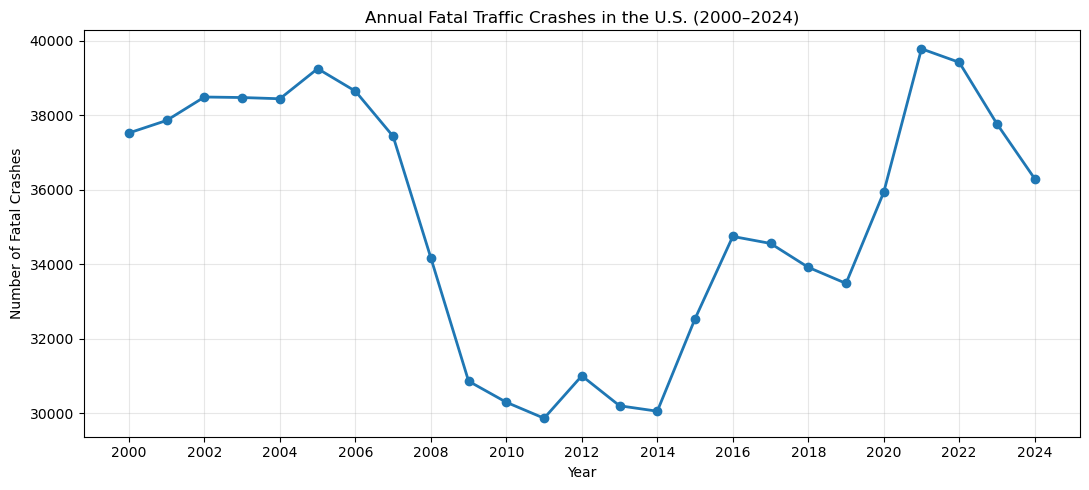

In [4]:

# Counting fatal crashes for each year
yearly_crashes = fars_full.groupby("year").size()

# Plotting the annual crash counts
plt.figure(figsize=(11, 5))
plt.plot(yearly_crashes.index, yearly_crashes.values,
         marker="o", linewidth=2)

plt.title("Annual Fatal Traffic Crashes in the U.S. (2000–2024)")
plt.xlabel("Year")
plt.ylabel("Number of Fatal Crashes")
plt.xticks(range(2000, 2025, 2))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Preliminary Findings: Annual Crash Trends

Fatal traffic crashes in the United States varied considerably between 2000 and 2024. Crash counts declined substantially between 2007 and 2013, followed by a general increase during the latter part of the study period, peaking in 2021.

These trends suggest that long-term changes in traffic safety may influence crash frequencies. Therefore, our statistical analysis of daylight saving time should account for differences between years.

This exploratory analysis does not establish a relationship between daylight saving time and fatal crashes.


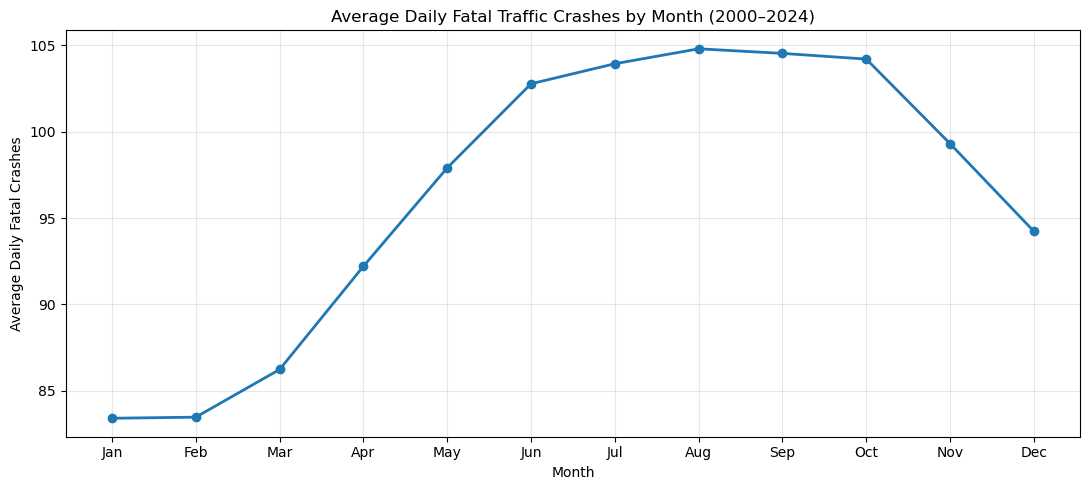

In [5]:

# Checking the number of crashes in each month
monthly_crashes = fars_full.groupby(["year", "month"]).size().reset_index(name="crashes")

# Calculating the number of days in each month
monthly_crashes["days"] = pd.to_datetime(
    monthly_crashes[["year", "month"]].assign(day=1)
).dt.days_in_month

# Finding the average daily crashes for each month
monthly_crashes["daily_average"] = (
    monthly_crashes["crashes"] / monthly_crashes["days"]
)

monthly_avg = monthly_crashes.groupby("month")["daily_average"].mean()

# Plotting the monthly averages
plt.figure(figsize=(11, 5))
plt.plot(monthly_avg.index, monthly_avg.values, marker="o", linewidth=2)

plt.title("Average Daily Fatal Traffic Crashes by Month (2000–2024)")
plt.xlabel("Month")
plt.ylabel("Average Daily Fatal Crashes")
plt.xticks(range(1, 13),
           ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
            "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [6]:
# Creating time periods
fars_full["period"] = pd.cut(
    fars_full["year"],
    bins=[1999, 2008, 2018, 2024],
    labels=["2000-2008", "2009-2018", "2019-2024"]
)

# Quick check
display(fars_full[["year", "period"]].drop_duplicates().sort_values("year").head(15))

,year,period
0,2000,2000-2008
37526,2001,2000-2008
75388,2002,2000-2008
113879,2003,2000-2008
152356,2004,2000-2008
190800,2005,2000-2008
230052,2006,2000-2008
268700,2007,2000-2008
306135,2008,2000-2008
340307,2009,2009-2018


In [7]:

# Counting crashes by year and month
monthly_period = (
    fars_full.groupby(["year", "month"])
    .size()
    .reset_index(name="crashes")
)

# Adding the time periods
monthly_period["period"] = pd.cut(
    monthly_period["year"],
    bins=[1999, 2008, 2018, 2024],
    labels=["2000-2008", "2009-2018", "2019-2024"]
)

# Calculating average daily crashes
monthly_period["days"] = pd.to_datetime(
    monthly_period[["year", "month"]].assign(day=1)
).dt.days_in_month

# Combining the crash counts and days for each period
monthly_period_avg = (
    monthly_period.groupby(["period", "month"], observed=True)
    .agg(crashes=("crashes", "sum"),
         days=("days", "sum"))
    .reset_index()
)

monthly_period_avg["daily_average"] = (
    monthly_period_avg["crashes"] / monthly_period_avg["days"]
)

display(monthly_period_avg.head())


,period,month,crashes,days,daily_average
0,2000-2008,1,25344,279,90.838710
1,2000-2008,2,23218,255,91.050980
2,2000-2008,3,25973,279,93.093190
3,2000-2008,4,27143,270,100.529630
4,2000-2008,5,29225,279,104.749104


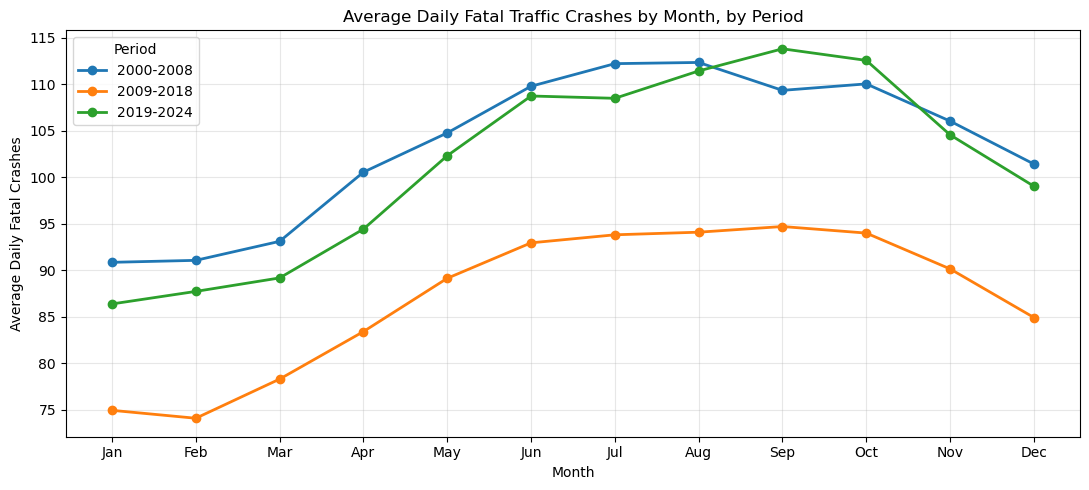

In [8]:

# Plotting monthly crash averages for each period
plt.figure(figsize=(11, 5))

for period in monthly_period_avg["period"].unique():
    temp = monthly_period_avg[
        monthly_period_avg["period"] == period
    ]

    plt.plot(
        temp["month"],
        temp["daily_average"],
        marker="o",
        linewidth=2,
        label=period
    )

plt.title("Average Daily Fatal Traffic Crashes by Month, by Period")
plt.xlabel("Month")
plt.ylabel("Average Daily Fatal Crashes")

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.grid(alpha=0.3)
plt.legend(title="Period")
plt.tight_layout()
plt.show()



## Daylight Saving Time Transition Analysis

Our primary objective is to examine whether fatal traffic crashes increase following the spring DST transition.

We will compare fatal crashes before and after the transitions from 2000 to 2024, accounting for changes in DST dates and seasonal crash patterns.


In [9]:

import calendar
from datetime import date, timedelta

# Finding the DST transition dates for each year
dst_dates = []

for year in range(2000, 2025):

    if year < 2007:
        spring_month = 4
        fall_month = 10
    else:
        spring_month = 3
        fall_month = 11

    # Finding the Sundays in each transition month
    spring_sundays = [
        day for day in calendar.monthcalendar(year, spring_month)
        if day[calendar.SUNDAY] != 0
    ]

    fall_sundays = [
        day for day in calendar.monthcalendar(year, fall_month)
        if day[calendar.SUNDAY] != 0
    ]

    if year < 2007:
        spring_day = spring_sundays[0][calendar.SUNDAY]
        fall_day = fall_sundays[-1][calendar.SUNDAY]
    else:
        spring_day = spring_sundays[1][calendar.SUNDAY]
        fall_day = fall_sundays[0][calendar.SUNDAY]

    dst_dates.append({
        "year": year,
        "spring_dst": date(year, spring_month, spring_day),
        "fall_dst": date(year, fall_month, fall_day)
    })

dst_dates = pd.DataFrame(dst_dates)

display(dst_dates)


,year,spring_dst,fall_dst
0,2000,2000-04-02,2000-10-29
1,2001,2001-04-01,2001-10-28
2,2002,2002-04-07,2002-10-27
3,2003,2003-04-06,2003-10-26
4,2004,2004-04-04,2004-10-31
5,2005,2005-04-03,2005-10-30
6,2006,2006-04-02,2006-10-29
7,2007,2007-03-11,2007-11-04
8,2008,2008-03-09,2008-11-02
9,2009,2009-03-08,2009-11-01
